# Experiment 6: Regression Models with Statistical Performance Measures
**Aim:** To develop and evaluate regression models for predicting a continuous health variable (Glucose) and assess them with statistical performance measures.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

Dataset shape: (768, 9)


In [2]:
# Predict Glucose (continuous) from the other health indicators
X = df.drop(columns=["Glucose","Outcome"]); y = df["Glucose"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (614, 7)  Test: (154, 7)


In [3]:
# Linear Regression vs Ridge Regression
for name, model in [("LinearRegression", LinearRegression()), ("Ridge", Ridge(alpha=1.0))]:
    model.fit(X_train, y_train)
    for split, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        pred = model.predict(Xs)
        rmse = np.sqrt(mean_squared_error(ys, pred)); r2 = r2_score(ys, pred)
        print(f"{name} {split}: RMSE={rmse:.2f}, R2={r2:.3f}")

LinearRegression Train: RMSE=27.72, R2=0.250
LinearRegression Test: RMSE=29.49, R2=0.136
Ridge Train: RMSE=27.72, R2=0.250
Ridge Test: RMSE=29.48, R2=0.136


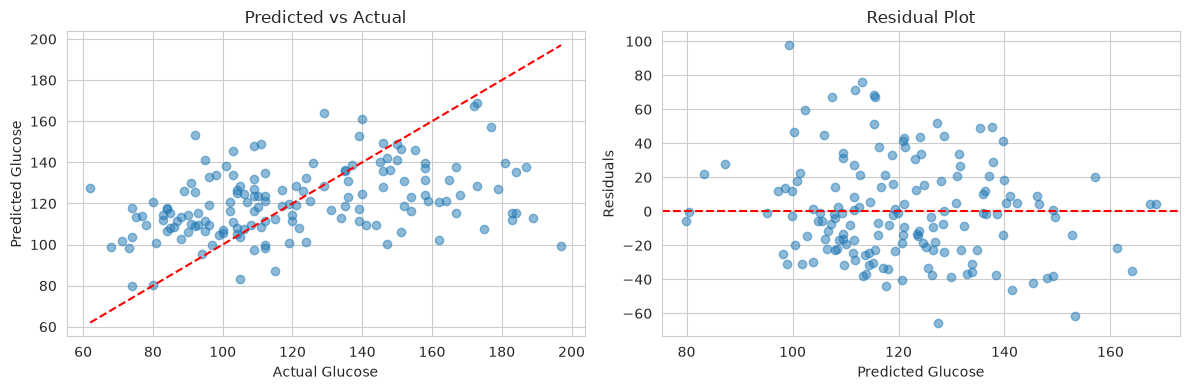

In [4]:
# Predicted vs Actual + Residual analysis (Ridge)
model = Ridge(alpha=1.0).fit(X_train, y_train)
pred = model.predict(X_test); resid = y_test - pred
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].scatter(y_test, pred, alpha=0.5); ax[0].plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],"r--")
ax[0].set(xlabel="Actual Glucose", ylabel="Predicted Glucose", title="Predicted vs Actual")
ax[1].scatter(pred, resid, alpha=0.5); ax[1].axhline(0, color="r", linestyle="--")
ax[1].set(xlabel="Predicted Glucose", ylabel="Residuals", title="Residual Plot")
plt.tight_layout(); plt.savefig("images/fig1_regression.png", dpi=130, bbox_inches="tight"); plt.show()

## Key Observations
- Ridge regression generalizes slightly better than plain linear regression.
- Residuals are roughly centered at zero, indicating a reasonable fit.
- Limitations: linear models miss non-linear relationships; invalid zero values add noise.